# 05 · Agua de dilución en el P&ID de A3110: `AIT 3105 → FFIC 3102 → FIRC 3103`

Estructura confirmada por el equipo:

| Tag | Función | Estado |
|---|---|---|
| `AIT 3105` | analizador de ClO₄⁻ en la corriente que entra al cristalizador; si viene alto, avisa a `FFIC 3102` | **retardo aún sin definir** → se trata como parámetro libre |
| `FFIC 3102` | controlador de **razón** dilución/alimentación; entrega la consigna a `FIRC 3103` | consigna = R × caudal de alimentación |
| `FIRC 3103` | controla el caudal de agua de dilución y abre o cierra la válvula | PI sintonizado por SIMC |
| `LIRCSAHL 3101`, `PIRCSAHL 3101` | nivel y vacío (temperatura) | de apoyo; cerrados en todos los casos |
| `DIRCAHL 3101` | densidad; su cascada con `FIRCAL 3101` **no** es el agua de dilución | actuador por identificar; aquí solo se mide |

**Supuesto de modelado:** `AIT 3105` mide el ClO₄⁻ de la alimentación *antes* de mezclar el agua (acción anticipada). La ley es mantener la mezcla en la concentración nominal: R = ClO₄ medido / ClO₄ objetivo − 1, con una ganancia `gain` entre 0 (sin compensar) y 1 (compensación total) y límites de razón. Si el analizador estuviera después de la dilución, sería un lazo de realimentación distinto.

Los parámetros de planta siguen siendo supuestos: los números son tendencias.

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))           # raíz del repo (donde está msmpr_core)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from msmpr_core.params import make_params, placeholders
from msmpr_core.plant import Plant, simulate
from msmpr_core import control as C
os.makedirs("../docs/fig", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

In [3]:
p = make_params()
pl = Plant(p)
x0, u0, d0 = pl.steady_state(alpha=0.25)
m0 = pl.metrics(x0, u0, d0)
q0, qs0 = u0["Q_dil_cmd"], d0["Q_stock"]
R0 = q0 / qs0
DT = 5.0
tun, info = C.autotune(pl, x0, u0, d0, dt_s=DT)
sp = {"T": x0[1], "V": x0[0], "rho": 0.0}
print(f"Dilución nominal {3600*q0:.2f} m3/h; razón nominal R0 = {R0:.4f}; ppm nominal {m0['ppm_ClO4']:.1f}; recuperación {m0['recovery_pct']:.1f} %")
print("FIRC 3103:", tun["flow"])

Dilución nominal 14.04 m3/h; razón nominal R0 = 0.0526; ppm nominal 35.7; recuperación 11.0 %
FIRC 3103: LoopTuning(Kp=0.8, Ki=0.1, Kd=0.0, direct=False)


## 1. ¿Cuánta agua haría falta para compensar un aumento de ClO₄⁻? (estático)
Para mantener la mezcla en su concentración nominal, la dilución debe crecer con el ClO₄⁻ de entrada. Se resuelve el estacionario con y sin esa compensación.

In [4]:
rows = []
for f in (1.05, 1.10, 1.25, 1.50):
    R = f*(1 + R0) - 1; Qd = R*qs0
    d = {**d0, "CP_stock": f*d0["CP_stock"]}
    xs, us, ds = pl.steady_state(alpha=0.25, d=d); ms = pl.metrics(xs, us, ds)                   # sin compensar
    xc, uc, dc = pl.steady_state(alpha=0.25, d=d, Q_dil=Qd); mc = pl.metrics(xc, uc, dc)       # con compensación total
    rows.append({"ClO4 de entrada x": f, "dilución necesaria [m3/h]": 3600*Qd, "veces la nominal": Qd/q0,
                 "ppm sin comp.": ms["ppm_ClO4"], "Y sin comp. %": ms["recovery_pct"],
                 "ppm con comp.": mc["ppm_ClO4"], "Y con comp. %": mc["recovery_pct"]})
req = pd.DataFrame(rows).set_index("ClO4 de entrada x"); req.round(2)

,dilución necesaria [m3/h],veces la nominal,ppm sin comp.,Y sin comp. %,ppm con comp.,Y con comp. %
ClO4 de entrada x,,,,,,
1.05,28.08,2.0,37.50,10.98,35.58,6.51
1.10,42.12,3.0,39.29,10.98,35.46,2.45
1.25,84.25,6.0,44.65,10.98,35.23,0.00
1.50,154.46,11.0,53.58,10.98,34.99,0.00


**Lectura.** Compensar el ClO₄⁻ con agua es caro: la dilución necesaria crece varias veces sobre la nominal y la recuperación de KNO₃ cae rápido, porque el agua baja la concentración de la alimentación hacia la solubilidad. Con los placeholders actuales (alimentación apenas sobre la solubilidad supuesta) el efecto es extremo; la **tendencia** (recuperación contra pureza) es lo que importa, y el tamaño de la válvula de dilución pasa a ser una restricción de diseño.

## 2. Etapa 1 · `FIRC 3103` solo
Consigna +15 % a los 10 min y pérdida de 20 % de ganancia de la válvula a los 30 min (ruido de medición 1 %). Muestreo de 2 s.

In [5]:
tun2, _ = C.autotune(pl, x0, u0, d0, dt_s=2.0)
flow_sp = lambda t: q0*(1.15 if t >= 600 else 1.0)
dist1 = lambda t: {**d0, "valve_gain": 0.8 if t >= 1800 else 1.0}
cl = simulate(pl, x0, 3600, 2.0, C.PlantController(pl, u0, sp, tun2, enabled=("flow",), flow_sp=flow_sp, noise_rel={"flow": 0.01}, seed=1), disturbance=dist1, log_every=5)
ol = simulate(pl, x0, 3600, 2.0, lambda t, x, pl_: {**u0, "Q_dil_cmd": flow_sp(t)}, disturbance=dist1, log_every=5)
late = lambda df: 100*abs(df.Qd.values[df.t_h.values > 0.9].mean()/(1.15*q0) - 1)
print(f"Error final tras la perturbación de válvula: FIRC 3103 {late(cl):.2f} %  |  válvula manual {late(ol):.2f} %")

Error final tras la perturbación de válvula: FIRC 3103 0.17 %  |  válvula manual 20.00 %


## 3. Etapa 2 · `FFIC 3102`: la dilución sigue al caudal de alimentación
La alimentación sube +12 % y +6 °C a las 2 h. Con razón fija, el caudal de dilución sube con ella.

In [6]:
Qs = lambda t: qs0*(1.12 if t >= 2*3600 else 1.0)
dist2 = lambda t: {**d0, "Q_stock": Qs(t), "T_feed": d0["T_feed"] + (6.0 if t >= 2*3600 else 0.0)}
H = 8*3600
fija = simulate(pl, x0, H, DT, C.PlantController(pl, u0, sp, tun, enabled=("T", "V", "flow")), disturbance=dist2, log_every=12)
razon = simulate(pl, x0, H, DT, C.PlantController(pl, u0, sp, tun, enabled=("T", "V", "ratio"), q_stock_meas=Qs, ratio_nom=R0), disturbance=dist2, log_every=12)
pd.DataFrame({"dilución final [m3/h]": {"consigna fija": 3600*fija.Qd.iloc[-1], "razón fija (FFIC 3102)": 3600*razon.Qd.iloc[-1]},
              "razón dilución/alimentación": {"consigna fija": fija.Qd.iloc[-1]/Qs(H), "razón fija (FFIC 3102)": razon.Qd.iloc[-1]/Qs(H)}}).round(4)

,dilución final [m3/h],razón dilución/alimentación
consigna fija,14.0415,0.0470
razón fija (FFIC 3102),15.7265,0.0526


## 4. Etapa 3 · `AIT 3105`: pulso de ClO₄⁻ y retardo del analizador
Pulso de **×1.25 en el ClO₄⁻ de alimentación entre las 3 h y las 5 h**. Como el retardo del analizador aún no está definido, se barre entre 0 y 2 h. Además: válvula de dilución limitada a 3× la nominal frente a una capaz de 8×, y compensación parcial (`gain` = 0.3).

In [7]:
def pulso(t): return d0["CP_stock"]*(1.25 if 3*3600 <= t < 5*3600 else 1.0)
dist3 = lambda t: {**d0, "CP_stock": pulso(t)}
H = 14*3600
def correr_ait(delay=None, cap=8.0, gain=1.0):
    if delay is None:
        ctrl = C.PlantController(pl, u0, sp, tun, enabled=("T", "V", "flow"))
    else:
        ctrl = C.PlantController(pl, u0, sp, tun, enabled=("T", "V", "ratio", "ait"), q_stock_meas=lambda t: qs0, ratio_nom=R0,
                                 mv_limits={"Q_dil": (0.0, cap*q0)}, ait={"cp_true": pulso, "delay_s": delay, "gain": gain, "R_max": 3*cap*R0})
    return simulate(pl, x0, H, DT, ctrl, disturbance=dist3, log_every=12)

casos = {"sin AIT (dilución fija)": correr_ait(None), "AIT, retardo 0": correr_ait(0.0), "AIT, retardo 15 min": correr_ait(900.0),
         "AIT, retardo 1 h": correr_ait(3600.0), "AIT, retardo 2 h": correr_ait(7200.0),
         "AIT, retardo 0, válvula 3x": correr_ait(0.0, cap=3.0), "AIT, retardo 0, ganancia 0.3": correr_ait(0.0, gain=0.3)}
rows = []
for name, df in casos.items():
    h = df.t_h.values; ppm = df.ppm_ClO4.values; Qd = 3600*df.Qd.values
    rows.append({"caso": name, "ppm pico": ppm.max(), "horas sobre 40 ppm": np.trapezoid((ppm > 40).astype(float), h),
                 "Y mínima %": df.recovery_pct.min(), "Y final %": df.recovery_pct.iloc[-1],
                 "dilución máx [m3/h]": Qd.max(), "agua extra [m3]": np.trapezoid(Qd - 3600*q0, h)})
tabla = pd.DataFrame(rows).set_index("caso"); tabla.round(2)

,ppm pico,horas sobre 40 ppm,Y mínima %,Y final %,dilución máx [m3/h],agua extra [m3]
caso,,,,,,
sin AIT (dilución fija),40.28,0.32,10.98,10.98,14.04,0.00
"AIT, retardo 0",35.72,0.00,0.09,11.05,84.25,140.41
"AIT, retardo 15 min",36.53,0.00,0.09,11.11,84.25,140.41
"AIT, retardo 1 h",38.42,0.00,0.09,11.23,84.25,140.41
"AIT, retardo 2 h",40.28,0.22,0.09,10.84,84.25,140.41
"AIT, retardo 0, válvula 3x",38.23,0.00,2.76,10.94,42.12,56.17
"AIT, retardo 0, ganancia 0.3",38.73,0.00,4.25,10.94,35.10,42.12


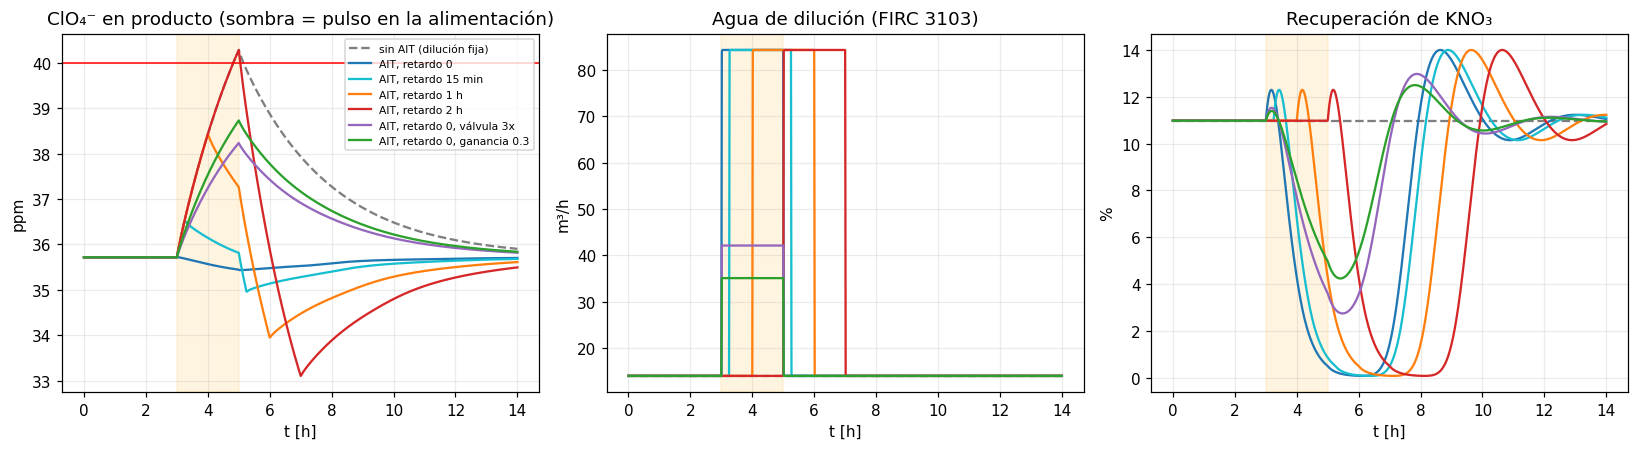

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True)
cols = ["tab:gray", "tab:blue", "tab:cyan", "tab:orange", "tab:red", "tab:purple", "tab:green"]
for (name, df), col in zip(casos.items(), cols):
    ls = "--" if name.startswith("sin") else "-"
    ax[0].plot(df.t_h, df.ppm_ClO4, color=col, ls=ls, label=name)
    ax[1].plot(df.t_h, 3600*df.Qd, color=col, ls=ls)
    ax[2].plot(df.t_h, df.recovery_pct, color=col, ls=ls)
ax[0].axhline(p["spec_ClO4_ppm_max"], color="r", lw=1); ax[0].legend(fontsize=7)
for a in ax: a.axvspan(3, 5, color="orange", alpha=0.12)
ax[0].set(xlabel="t [h]", ylabel="ppm", title="ClO₄⁻ en producto (sombra = pulso en la alimentación)")
ax[1].set(xlabel="t [h]", ylabel="m³/h", title="Agua de dilución (FIRC 3103)"); ax[2].set(xlabel="t [h]", ylabel="%", title="Recuperación de KNO₃")
fig.tight_layout(); fig.savefig("../docs/fig/05_AIT3105_retardo.png"); plt.show()

## Lectura
* **Sin `AIT`:** el pulso apenas supera el límite provisional de 40 ppm, porque el ppm responde lento (la purga arrastra el ClO₄ en horas) y el pulso es corto.
* **Con `AIT` sin retardo:** la compensación total mantiene el ppm, pero **anula la recuperación** mientras dura el pulso y gasta agua adicional del orden de cientos de m³. La compensación total no es una buena ley económica.
* **Retardo:** a 15 min casi no cambia nada; con retardos de una a dos horas (comparables con el pulso) el agua llega cuando el pulso ya pasó: se gasta la misma agua y el ppm pico vuelve a lo del caso sin analizador. **El retardo importa si el pulso es corto frente a él**, por eso hay que definirlo.
* **Válvula de 3×:** limita el daño a la recuperación pero también la compensación.
* **Ganancia parcial:** es la palanca para negociar ppm contra recuperación; su valor debe salir de una evaluación económica (pérdida por producto fuera de norma frente a producción perdida).

**No se modela:** ruido y deriva del analizador, la ubicación exacta del punto de muestreo, tiempos muertos de transporte entre el analizador y la válvula, ni lógica de alarmas (AHL). Faltan por definir: retardo de `AIT 3105`, ganancia y límites de `FFIC 3102`, capacidad real de la válvula de `FIRC 3103`.